In [ ]:
from pathlib import Path

# Локально репозиторий уже открыт. В Colab/Kaggle загружаем его с GitHub.
hosted = Path("/kaggle/working").is_dir() or Path("/content").is_dir()
if hosted:
    work_dir = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path("/content")
    repo_dir = work_dir / "recsys-rl-sequential"
    if repo_dir.exists():
        !git -C {repo_dir} pull --ff-only
    else:
        !git clone https://github.com/daosistt/recsys-rl-sequential {repo_dir}
    %cd {repo_dir}
    %pip install -q -r requirements.txt


In [ ]:
from src import config as project_config

# Kaggle: данные из подключённого dataset, результаты в /kaggle/working/artifacts.
# Colab: данные и результаты на Drive; для чтения данные копируются в /content.
# Локально: папки data и artifacts проекта.
# Свои пути можно задать через RECSYS_DATA_DIR и RECSYS_ARTIFACTS_DIR.
project_config.setup_paths()
from src.config import *
from src.prepare_data import load_yambda_data, train_val_test_split
from src.vocabulary import Vocabulary
from src.dataset import RecDataset
from src.train import plot_loss, train_loop
from src.evaluation import (
    load_model,
    prepare_evaluation_data,
    recommend_top_k,
    evaluate_metrics,
)

print(f"Данные: {DATA_DIR}")
print(f"Результаты: {ARTIFACTS_DIR}")
print(f"Устройство: {device}")


In [ ]:
torch.manual_seed(TRAIN_PARAMS["seed"])
np.random.seed(TRAIN_PARAMS["seed"])

run_dir = ARTIFACTS_DIR / (
    f"baseline_t4_{TRAIN_PARAMS['data_size']}_minfreq{TRAIN_PARAMS['min_frequency']}"
)
run_dir.mkdir(parents=True, exist_ok=True)

df = load_yambda_data(size=TRAIN_PARAMS["data_size"])
train, val, test = train_val_test_split(df)

vocab = Vocabulary(train, min_frequency=TRAIN_PARAMS["min_frequency"])
with open(run_dir / "vocab.pkl", "wb") as f:
    pickle.dump(vocab, f)
with open(run_dir / "experiment_config.json", "w") as f:
    json.dump({"training": TRAIN_PARAMS, "model": GPT2_PARAMS, "split": train.attrs}, f, indent=2)

seq_len = GPT2_PARAMS["n_positions"]
train_ds = RecDataset(train, vocab, seq_len=seq_len)
val_ds = RecDataset(val, vocab, seq_len=seq_len, context=train)

print(f"Train users: {len(train)}, vocabulary: {len(vocab)}")
print(f"Train windows: {len(train_ds)}, validation windows: {len(val_ds)}")
print(f"Результаты: {run_dir}")

In [4]:
config = GPT2Config(
    **GPT2_PARAMS,
    vocab_size=len(vocab),
    pad_token_id=vocab.pad_idx,
)
model = GPT2LMHeadModel(config).to(device)

optimizer = AdamW(
    model.parameters(),
    lr=TRAIN_PARAMS["lr"],
    weight_decay=TRAIN_PARAMS["weight_decay"],
)
train_loader = DataLoader(train_ds, batch_size=TRAIN_PARAMS["batch_size"], shuffle=True)
val_loader = DataLoader(val_ds, batch_size=TRAIN_PARAMS["batch_size"], shuffle=False)

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Train batches per epoch: {len(train_loader)}")

Model parameters: 30,085,760
Train batches per epoch: 1839


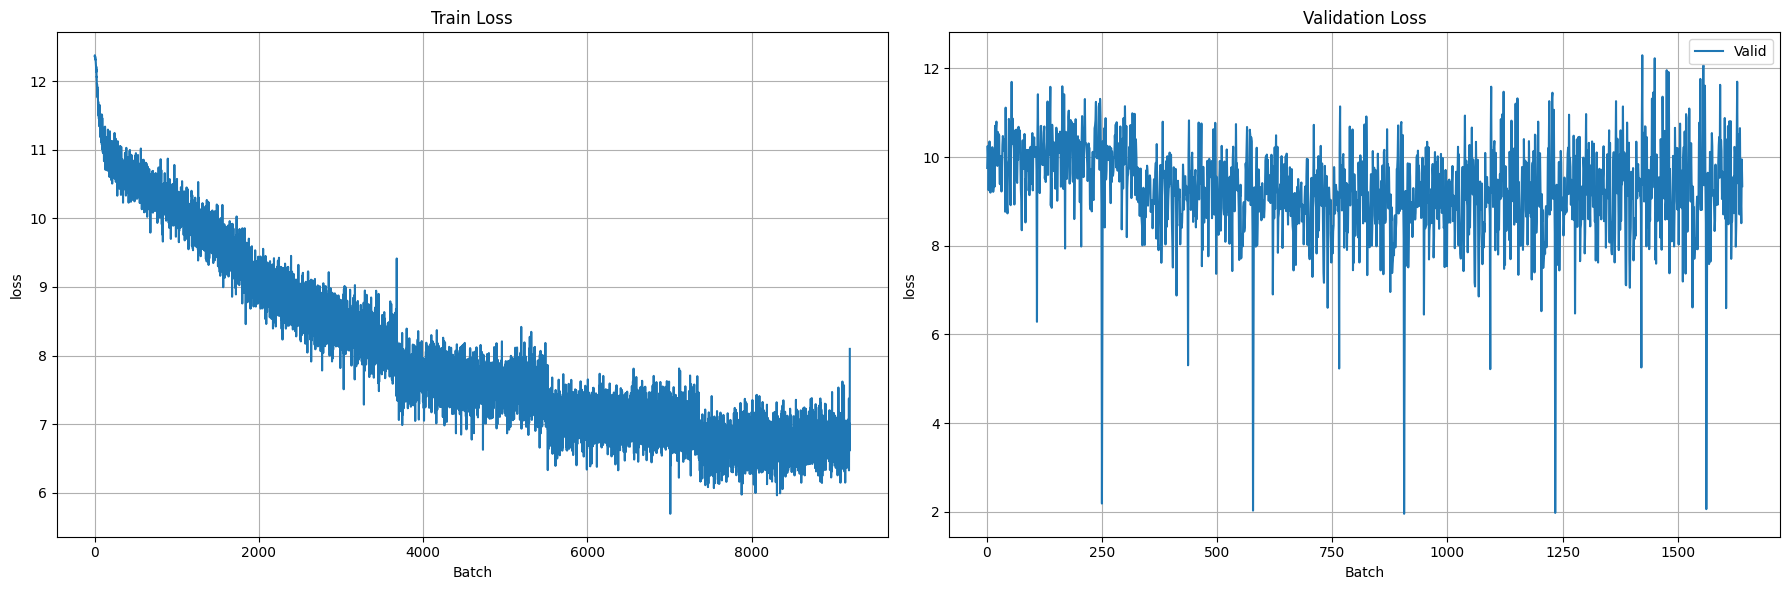

Epoch 5/5: train loss = 6.7322, val loss = 9.2969


In [5]:
loss_history = train_loop(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs=TRAIN_PARAMS["num_epochs"],
    checkpoint_dir=run_dir / "checkpoints",
    plot_every=TRAIN_PARAMS["plot_every"],
)

In [ ]:
# Оцениваем best.pt из папки текущего эксперимента.
artifact_dir = ARTIFACTS_DIR / f"baseline_t4_{TRAIN_PARAMS['data_size']}_minfreq{TRAIN_PARAMS['min_frequency']}"
ks = (5, 10, 20)

eval_model, eval_vocab, saved_config = load_model(artifact_dir, device)
eval_df = load_yambda_data(size=saved_config["training"]["data_size"])
eval_train, eval_val, eval_test = train_val_test_split(eval_df, **saved_config["split"])

contexts, targets = prepare_evaluation_data(
    eval_train, eval_val, eval_test, eval_vocab, eval_model.config.n_positions,
)
recommendations = recommend_top_k(eval_model, contexts, eval_vocab, k=max(ks), batch_size=8)
metrics = evaluate_metrics(recommendations, targets, ks)

unknown_targets = sum(actual[0] not in eval_vocab for actual in targets)
print(f"Примеров: {len(targets)}, неизвестных целей: {unknown_targets / len(targets):.1%}")
metrics
